# 13 팀 모델 B: EMA를 기본으로, 코사인·에폭 수 비교와 과적합 지표

12에서 가중치 평균(EMA, 감쇠 0.999)이 가장 좋고 가장 안정적이었습니다(E29: 최고 F1 0.9477, 마지막 5에폭 0.9451 ± 0.0003). 여기서는 EMA를 기본으로 두고 **한 번에 하나씩** 바꿉니다. 그리고 과적합을 숫자로 판단할 지표를 매 에폭 잽니다.

| 번호 | 설정 | 비교 상대 | 확인하려는 것 |
|---|---|---|---|
| E29r | EMA, 40에폭, 학습률 1e-3 고정 (12의 E29 다시 실행) | 12의 E29 | 같은 결과가 다시 나오는가, 과적합 지표의 기준값 |
| E30 | E29r + **코사인 학습률** | E29r | EMA에 코사인을 더하면 더 좋아지는가 |
| E31 | E29r에서 **에폭 30** | E29r | 30에폭이면 충분한가 (12에서 E29의 검증 손실은 22에폭에 가장 낮았음) |

과적합 지표 (매 에폭, 평가 모드로 같은 조건에서 잼)

| 지표 | 계산 | 과적합이면 |
|---|---|---|
| 학습 F1 − 검증 F1 | 학습 묶음에서 클래스 비율대로 뽑은 9,400개(검증과 같은 수)와 검증 9,400개의 매크로 F1 차이 | 학습 F1은 오르는데 차이가 계속 벌어짐 |
| 검증 손실 − 학습 손실 | 위 두 묶음의 교차 엔트로피 차이 | 차이가 계속 벌어짐 |
| 검증 손실 상승폭 | 마지막 에폭 검증 손실 − 가장 낮았던 검증 손실, 그리고 가장 낮았던 에폭 | 상승폭이 크고 최저 에폭이 이름 |

12의 학습 손실은 학습 모드(배치 정규화가 배치 통계를 씀)에서 가중치가 바뀌는 도중에 잰 평균이라 검증 손실과 바로 비교할 수 없었습니다. 여기서는 두 묶음을 같은 모델·같은 모드로 평가합니다. EMA 실험은 평가에 쓰는 EMA 모델로 잽니다.

- 구조, 배치 256, 데이터(79,392개), 검증 묶음은 12와 같습니다. 시드 2개. 5에폭마다 진행 상황을 출력합니다.
- 예상 시간: 40에폭 2번 × 2 + 30에폭 × 2, 12의 Kaggle T4 실측 에폭당 8.4초에 학습 묶음 평가 시간을 더해 약 40분(어림).
- 시험 묶음은 쓰지 않습니다.

In [9]:
# 셀 1. 설정과 버전
import os, sys, time, random, copy, urllib.request
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torchaudio
import soundfile as sf
from torch.optim.swa_utils import AveragedModel, get_ema_multi_avg_fn
import matplotlib.pyplot as plt

SMOKE = False                  # True: 단어마다 몇 개만, 짧게 (결과 숫자는 쓰지 않음)
USE_DRIVE = False              # True: Colab에서 Google Drive를 연결해 스펙트로그램을 Drive에 저장·재사용 (10·11에서 저장한 것 사용)
SEEDS = [0, 1]
RUNS_SPEC = {                  # 번호: (에폭, 학습률 스케줄, EMA)
    "E29r": (40, "고정", True),
    "E30": (40, "코사인", True),
    "E31": (30, "고정", True),
}
N_TRAIN_EVAL = 9400            # 과적합 지표용: 학습 묶음에서 클래스 비율대로 뽑아 매 에폭 평가하는 개수 (검증 묶음과 같은 수)
EMA_DECAY = 0.999
CONDS = {"E15": 153, "E16": None}   # 셀 2(09와 같은 코드)가 출력에 씀
FOLD_SEED = 0
DATA_ROOT = "data"
CSV = "splits_11class.csv"
CSV_URL = "https://raw.githubusercontent.com/yuchanghun/DL_26_02_Team2/main/splits_11class.csv"
CACHE_DIR = "cache"
SR = 16000
COMMANDS = ["yes", "no", "up", "down", "left", "right", "on", "off", "stop", "go"]
DIGITS = ["zero", "one", "two", "three", "four", "five", "six", "seven", "eight", "nine"]
AUX = ["bed", "bird", "cat", "dog", "happy", "house", "marvin", "sheila", "tree", "wow"]
UNSEEN = ["backward", "follow", "forward", "learn", "visual"]
OTHER = "other"
LABELS = COMMANDS + [OTHER]
K = len(LABELS)
B_EPOCHS, B_LR, B_BATCH = 20, 1e-3, 256          # 09와 같음 (에폭은 실험마다 RUNS_SPEC으로 바꿈)
B_CHANNELS = [16, 32, 64, 128]

if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    CACHE_DIR = "/content/drive/MyDrive/DL_T02_cache"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP = device.type == "cuda"
if SMOKE:
    CONDS = {"E15": 3, "E16": None}
    RUNS_SPEC = {k: (max(2, e // 10), s, m) for k, (e, s, m) in RUNS_SPEC.items()}
print("python", sys.version.split()[0], "| torch", torch.__version__, "| torchaudio", torchaudio.__version__, "| pandas", pd.__version__)
print("device:", device, "|", torch.cuda.get_device_name(0) if AMP else "GPU 없음 → CPU", "| SMOKE", SMOKE, "| 저장 위치", CACHE_DIR)

python 3.13.16 | torch 2.11.0+cu130 | torchaudio 2.11.0+cu130 | pandas 2.3.3
device: cuda | Tesla T4 | SMOKE False | 저장 위치 cache


In [10]:
# 셀 2. 데이터 (08·09와 같은 구성. 4묶음은 여기서 쓰지 않음)
os.makedirs(DATA_ROOT, exist_ok=True)
sc = torchaudio.datasets.SPEECHCOMMANDS(DATA_ROOT, download=True, subset="training")    # 공식 학습 목록 (검증·시험 목록 제외)
BASE_DIR = os.path.dirname(sc._path)
if not os.path.exists(CSV):
    urllib.request.urlretrieve(CSV_URL, CSV)
table = pd.read_csv(CSV)
table = table[table.split.isin(["train", "val"])].reset_index(drop=True)      # 시험 묶음은 쓰지 않음
base_train = table[table.split == "train"]

rows = []
for i in range(len(sc)):
    path, _, word, spk, _ = sc.get_metadata(i)
    if word in COMMANDS or word in UNSEEN:
        continue
    rows.append({"split": "train", "path": path.replace("\\", "/"), "word": word, "speaker": spk,
                 "label": OTHER, "group": "seen_other", "start": 0, "gain": 1.0})
pool = pd.DataFrame(rows)
assert sorted(pool.word.unique()) == sorted(DIGITS + AUX)
used = set(base_train[base_train.group == "seen_other"].path)
assert used <= set(pool.path)
rng = np.random.default_rng(0)
pool["first"] = ~pool.path.isin(used)                        # 08과 같은 순서: 07에서 쓴 153개가 먼저
pool["rnd"] = rng.random(len(pool))
pool = pool.sort_values(["word", "first", "rnd"]).drop(columns=["first", "rnd"])
pool["rank"] = pool.groupby("word").cumcount()

rest = base_train[base_train.group != "seen_other"].assign(rank=-1)
if SMOKE:
    rest = rest.groupby("label").head(10)
    pool = pool[pool["rank"] < 20]
train_all = pd.concat([rest, pool], ignore_index=True)
val = table[table.split == "val"].reset_index(drop=True)
if SMOKE:
    val = val.groupby(["label", "group", "word"], group_keys=False).sample(frac=1.0, random_state=0)
    val = val.groupby(["label", "group", "word"]).head(3).reset_index(drop=True)
L2I = {l: i for i, l in enumerate(LABELS)}
Y_ALL = torch.tensor(train_all.label.map(L2I).values)
Y_VAL = torch.tensor(val.label.map(L2I).values)
TRAIN_WORD = train_all.word.to_numpy(copy=True)
VAL_WORD = val.word.to_numpy(copy=True)

# 단어 4묶음: 숫자 3·3·2·2개 + 보조 단어 2·2·3·3개
fr = np.random.default_rng(FOLD_SEED)
d, a = list(fr.permutation(DIGITS)), list(fr.permutation(AUX))
FOLDS, i_d, i_a = [], 0, 0
for nd, na in [(3, 2), (3, 2), (2, 3), (2, 3)]:
    FOLDS.append([str(w) for w in sorted(d[i_d:i_d + nd]) + sorted(a[i_a:i_a + na])])
    i_d += nd; i_a += na
assert sorted(sum(FOLDS, [])) == sorted(DIGITS + AUX)

def train_mask(n, held):
    keep_n = (train_all.group != "seen_other") | (n is None) | (train_all["rank"] < (n or 0))
    return (keep_n & ~train_all.word.isin(held)).to_numpy(copy=True)

for f, held in enumerate(FOLDS):
    print(f"묶음 {f + 1}: 학습에서 뺄 단어 {held}")
    for eid, n in CONDS.items():
        m = train_mask(n, held)
        k = int((Y_ALL[torch.from_numpy(m)] == L2I[OTHER]).sum())
        print(f"   {eid} (단어마다 {n if n else '전부'}): 학습 {m.sum():,}개, '명령 아님' {k:,}개 ({k / m.sum():.1%}), "
              f"검증에서 뺀 단어 {np.isin(VAL_WORD, held).sum():,}개")

묶음 1: 학습에서 뺄 단어 ['four', 'six', 'two', 'cat', 'wow']
   E15 (단어마다 153): 학습 34,064개, '명령 아님' 3,295개 (9.7%), 검증에서 뺀 단어 1,469개
   E16 (단어마다 전부): 학습 66,857개, '명령 아님' 36,088개 (54.0%), 검증에서 뺀 단어 1,469개
묶음 2: 학습에서 뺄 단어 ['five', 'seven', 'three', 'dog', 'marvin']
   E15 (단어마다 153): 학습 34,064개, '명령 아님' 3,295개 (9.7%), 검증에서 뺀 단어 1,502개
   E16 (단어마다 전부): 학습 66,560개, '명령 아님' 35,791개 (53.8%), 검증에서 뺀 단어 1,502개
묶음 3: 학습에서 뺄 단어 ['nine', 'zero', 'bed', 'happy', 'tree']
   E15 (단어마다 153): 학습 34,064개, '명령 아님' 3,295개 (9.7%), 검증에서 뺀 단어 1,331개
   E16 (단어마다 전부): 학습 68,339개, '명령 아님' 37,570개 (55.0%), 검증에서 뺀 단어 1,331개
묶음 4: 학습에서 뺄 단어 ['eight', 'one', 'bird', 'house', 'sheila']
   E15 (단어마다 153): 학습 34,064개, '명령 아님' 3,295개 (9.7%), 검증에서 뺀 단어 1,278개
   E16 (단어마다 전부): 학습 68,189개, '명령 아님' 37,420개 (54.9%), 검증에서 뺀 단어 1,278개


In [11]:
# 셀 3. 소리 읽기 → 로그 멜 (07·08과 같은 설정, 저장해 두고 다시 씀)
def load_row(r):
    """06 노트북과 같은 규칙: 잡음은 start부터 1초를 잘라 gain을 곱함, 단어는 1초로 맞춤"""
    if r.group == "noise":
        x, _ = sf.read(os.path.join(BASE_DIR, r.path), dtype="float32", start=int(r.start), frames=SR)
        x = x * float(r.gain)
    else:
        x, _ = sf.read(os.path.join(BASE_DIR, r.path), dtype="float32")
    return np.pad(x, (0, max(0, SR - len(x))))[:SR]

class Rows(torch.utils.data.Dataset):
    def __init__(self, df):
        self.df = df
    def __len__(self):
        return len(self.df)
    def __getitem__(self, i):
        return load_row(self.df.iloc[i])

def cached(name, fn):
    path = os.path.join(CACHE_DIR, f"{name}{'_smoke' if SMOKE else ''}.pt")
    if os.path.exists(path):
        d = torch.load(path)
        print(f"  {name}: 저장된 것 사용 (처음 계산 {d['sec']:.0f}초)")
        return d
    d = fn()
    os.makedirs(CACHE_DIR, exist_ok=True)
    torch.save(d, path)
    return d

mel = torchaudio.transforms.MelSpectrogram(sample_rate=SR, n_fft=400, hop_length=160, n_mels=64).to(device)
to_db = torchaudio.transforms.AmplitudeToDB(stype="power", top_db=80).to(device)

def spec(df, name):
    def run():
        M, t0 = [], time.time()
        dl = torch.utils.data.DataLoader(Rows(df), batch_size=256, shuffle=False,
                                         num_workers=2 if os.name != "nt" else 0, collate_fn=lambda b: np.stack(b))
        with torch.no_grad():
            for x in dl:
                M.append(to_db(mel(torch.from_numpy(x).to(device))).half().cpu())
        d = {"mel": torch.cat(M).unsqueeze(1), "sec": time.time() - t0}
        print(f"  {name}: 로그 멜 {tuple(d['mel'].shape)} ({d['sec']:.0f}초)")
        return d
    return cached(name, run)

MEL_ALL = spec(train_all, "spec08_train_pool")["mel"]           # 08과 같은 이름·순서 → 저장된 게 있으면 다시 씀
MEL_VAL = spec(val, "spec09_val" if SMOKE else "spec11_val")["mel"]
assert len(MEL_ALL) == len(train_all) and len(MEL_VAL) == len(val)

  spec08_train_pool: 저장된 것 사용 (처음 계산 26초)
  spec11_val: 저장된 것 사용 (처음 계산 3초)


In [12]:
# 셀 4. 평가 함수와 팀 모델 B (08과 같은 CNN·학습, 에폭 선택만 뺀 단어 제외)
def evaluate(pred, held):
    """held: 학습에서 뺀 단어. 지표를 뺀 단어 / 남은 단어 / 잡음으로 나눠 계산"""
    p, t = pred.cpu().numpy(), Y_VAL.numpy()
    oth = L2I[OTHER]
    is_held = np.isin(VAL_WORD, held)
    sel = ~is_held                                           # 에폭 선택용: 뺀 단어 제외
    cm = np.bincount(t[sel] * K + p[sel], minlength=K * K).reshape(K, K).astype(float)
    tp = np.diag(cm)
    prec, rec = tp / np.maximum(cm.sum(0), 1), tp / np.maximum(cm.sum(1), 1)
    f1 = 2 * prec * rec / np.maximum(prec + rec, 1e-12)
    is_cmd = t != oth
    known = (val.group.values == "seen_other") & ~is_held
    noise = val.group.values == "noise"
    return {"f1": float(f1.mean()), "acc": float(tp.sum() / cm.sum()),
            "fa_held": float(np.mean(p[is_held] != oth)) if is_held.any() else float("nan"),
            "fa_known": float(np.mean(p[known] != oth)),
            "fa_noise": float(np.mean(p[noise] != oth)) if noise.any() else float("nan"),
            "miss": float(np.mean(p[is_cmd] == oth)),
            "confuse": float(np.mean((p[is_cmd] != oth) & (p[is_cmd] != t[is_cmd]))),
            "pred": p}

class KWSCNN(nn.Module):
    def __init__(self, channels=B_CHANNELS, n_classes=K):
        super().__init__()
        blocks, c_in = [], 1
        for c in channels:
            blocks += [nn.Conv2d(c_in, c, 3, padding=1), nn.BatchNorm2d(c), nn.ReLU(inplace=True), nn.MaxPool2d(2)]
            c_in = c
        self.features = nn.Sequential(*blocks)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(c_in, n_classes)
    def forward(self, x):
        return self.fc(self.pool(self.features(x)).flatten(1))

def train_cnn(mask, seed, held):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    m = torch.from_numpy(mask)
    Xtr = MEL_ALL[m].float()
    MU, SD = Xtr.mean().item(), Xtr.std().item()
    Xtr = ((Xtr - MU) / SD).to(device); Ytr = Y_ALL[m].to(device)
    Xva = ((MEL_VAL.float() - MU) / SD).to(device)
    cnn = KWSCNN().to(device)
    opt = torch.optim.Adam(cnn.parameters(), lr=B_LR)
    scaler = torch.amp.GradScaler(enabled=AMP)
    best, hist, t_start = None, [], time.time()
    for ep in range(B_EPOCHS):
        cnn.train(); t0 = time.time(); tot = 0.0
        perm = torch.randperm(len(Xtr), device=device)
        for i in range(0, len(Xtr), B_BATCH):
            idx = perm[i:i + B_BATCH]
            with torch.autocast(device.type, dtype=torch.float16, enabled=AMP):
                loss = nn.functional.cross_entropy(cnn(Xtr[idx]).float(), Ytr[idx])
            opt.zero_grad(); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot += loss.item() * len(idx)
        cnn.eval()
        with torch.no_grad(), torch.autocast(device.type, dtype=torch.float16, enabled=AMP):
            pred = torch.cat([cnn(Xva[i:i + 1024]).argmax(1) for i in range(0, len(Xva), 1024)])
        r = evaluate(pred, held)
        hist.append({"loss": tot / len(Xtr), "f1": r["f1"], "fa_held": r["fa_held"], "fa_known": r["fa_known"], "sec": time.time() - t0})
        if best is None or r["f1"] > best["f1"]:
            best = {**r, "epoch": ep + 1}
    del Xtr, Xva
    if AMP:
        torch.cuda.empty_cache()
    best["sec"] = time.time() - t_start
    return best, pd.DataFrame(hist)

In [13]:
# 셀 5. 학습 함수 (12와 같은 학습) + 매 에폭 학습 묶음 일부와 검증 묶음을 같은 조건(평가 모드)으로 평가
MASK_ALL = train_mask(None, [])                 # "명령 아님" 전부 = 08의 E13, 12와 같은 학습 데이터
# 과적합 지표용 학습 묶음 표본: 학습 데이터에서 클래스(라벨) 비율대로 N_TRAIN_EVAL개, 시드와 무관하게 고정
_idx_all = np.where(MASK_ALL)[0]
_lab = Y_ALL.numpy()[_idx_all]
_rng = np.random.default_rng(12345)
_pick = []
for c in range(K):
    ic = _idx_all[_lab == c]
    n_c = int(round(N_TRAIN_EVAL * len(ic) / len(_idx_all)))
    _pick.append(_rng.choice(ic, size=min(n_c, len(ic)), replace=False))
TRAIN_EVAL_IDX = np.sort(np.concatenate(_pick))
print(f"과적합 지표용 학습 표본 {len(TRAIN_EVAL_IDX):,}개 (학습 {MASK_ALL.sum():,}개 중, 클래스 비율 유지)")

def macro_f1(pred, y):
    cm = np.bincount(y * K + pred, minlength=K * K).reshape(K, K).astype(float)
    tp = np.diag(cm)
    prec, rec = tp / np.maximum(cm.sum(0), 1), tp / np.maximum(cm.sum(1), 1)
    return float((2 * prec * rec / np.maximum(prec + rec, 1e-12)).mean())

def logits_of(model, X):
    model.eval()
    with torch.no_grad(), torch.autocast(device.type, dtype=torch.float16, enabled=AMP):
        return torch.cat([model(X[i:i + 1024]) for i in range(0, len(X), 1024)]).float()

def train_b(seed, epochs, sched, ema, tag):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    m = torch.from_numpy(MASK_ALL)
    Xtr = MEL_ALL[m].float()
    MU, SD = Xtr.mean().item(), Xtr.std().item()
    Xtr = ((Xtr - MU) / SD).to(device); Ytr = Y_ALL[m].to(device)
    Xva = ((MEL_VAL.float() - MU) / SD).to(device); Yva = Y_VAL.to(device)
    Xte = ((MEL_ALL[torch.from_numpy(TRAIN_EVAL_IDX)].float() - MU) / SD).to(device)
    Yte = Y_ALL[torch.from_numpy(TRAIN_EVAL_IDX)].to(device)
    cnn = KWSCNN().to(device)
    opt = torch.optim.Adam(cnn.parameters(), lr=B_LR)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs) if sched == "코사인" else None
    ema_model = AveragedModel(cnn, multi_avg_fn=get_ema_multi_avg_fn(EMA_DECAY), use_buffers=True) if ema else None
    scaler = torch.amp.GradScaler(enabled=AMP)
    hist, best, t_start = [], None, time.time()
    for ep in range(epochs):
        cnn.train(); t0 = time.time()
        perm = torch.randperm(len(Xtr), device=device)
        for i in range(0, len(Xtr), B_BATCH):
            idx = perm[i:i + B_BATCH]
            with torch.autocast(device.type, dtype=torch.float16, enabled=AMP):
                loss = nn.functional.cross_entropy(cnn(Xtr[idx]).float(), Ytr[idx])
            opt.zero_grad(); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            if ema_model is not None:
                ema_model.update_parameters(cnn)
        lr_now = opt.param_groups[0]["lr"]
        if scheduler is not None:
            scheduler.step()
        model = ema_model if ema_model is not None else cnn
        lv, lt = logits_of(model, Xva), logits_of(model, Xte)
        vloss = nn.functional.cross_entropy(lv, Yva).item()
        tloss = nn.functional.cross_entropy(lt, Yte).item()
        pred = lv.argmax(1)
        r = evaluate(pred, [])
        tf1 = macro_f1(lt.argmax(1).cpu().numpy(), Yte.cpu().numpy())
        hist.append({"epoch": ep + 1, "train_f1": tf1, "f1": r["f1"], "gap_f1": tf1 - r["f1"],
                     "train_loss": tloss, "val_loss": vloss, "gap_loss": vloss - tloss,
                     "fa": r["fa_known"], "miss": r["miss"], "lr": lr_now, "sec": time.time() - t0})
        if best is None or r["f1"] > best["f1"]:
            best = {**r, "epoch": ep + 1}
        if (ep + 1) % 5 == 0 or ep + 1 == epochs:
            print(f"    [{tag} 시드 {seed}] 에폭 {ep + 1:2d}/{epochs} | F1 학습 {tf1:.4f} 검증 {r['f1']:.4f} (차이 {tf1 - r['f1']:+.4f}) | "
                  f"손실 학습 {tloss:.4f} 검증 {vloss:.4f} (차이 {vloss - tloss:+.4f}) | 오작동 {r['fa_known']:.3f} 놓침 {r['miss']:.3f} | "
                  f"학습률 {lr_now:.2e} | {time.time() - t_start:.0f}초 경과")
    last = {**r, "epoch": epochs}
    del Xtr, Xva, Xte
    if AMP:
        torch.cuda.empty_cache()
    return best, last, pd.DataFrame(hist)

과적합 지표용 학습 표본 9,400개 (학습 79,392개 중, 클래스 비율 유지)


In [14]:
# 셀 6. 학습: 실험 3개 × 시드 2개 (매번 처음부터)
RUNS = []
t_all = time.time()
for eid, (epochs, sched, ema) in RUNS_SPEC.items():
    for seed in SEEDS:
        print(f"{eid}: {epochs}에폭, 학습률 {sched}, EMA {'있음' if ema else '없음'}, 시드 {seed} 시작 (전체 {time.time() - t_all:.0f}초 경과)")
        best, last, h = train_b(seed, epochs, sched, ema, eid)
        late = h.iloc[-5:]
        vmin_ep = int(h.val_loss.idxmin()) + 1
        RUNS.append({"번호": eid, "에폭": epochs, "학습률": sched, "시드": seed, "best": best, "last": last, "hist": h,
                     "최고 에폭": best["epoch"], "마지막5 평균": late.f1.mean(), "마지막5 표준편차": late.f1.std(ddof=0),
                     "마지막 학습 F1": h.train_f1.iloc[-1], "마지막 F1 차이": h.gap_f1.iloc[-1], "마지막 손실 차이": h.gap_loss.iloc[-1],
                     "최저 검증 손실": h.val_loss.min(), "최저 에폭": vmin_ep, "검증 손실 상승폭": h.val_loss.iloc[-1] - h.val_loss.min(),
                     "에폭당 초": h.sec.mean()})
        print(f"  → 최고 F1 {best['f1']:.4f} ({best['epoch']}에폭) | 마지막 F1 {last['f1']:.4f} | 마지막 5에폭 {late.f1.mean():.4f} ± {late.f1.std(ddof=0):.4f} | "
              f"마지막 F1 차이(학습−검증) {h.gap_f1.iloc[-1]:+.4f} | 검증 손실 최저 {h.val_loss.min():.4f} ({vmin_ep}에폭), 마지막까지 상승 {h.val_loss.iloc[-1] - h.val_loss.min():+.4f} | "
              f"에폭당 {h.sec.mean():.1f}초")
print(f"전체 {time.time() - t_all:.0f}초")

E29r: 40에폭, 학습률 고정, EMA 있음, 시드 0 시작 (전체 0초 경과)
    [E29r 시드 0] 에폭  5/40 | F1 학습 0.2426 검증 0.2272 (차이 +0.0154) | 손실 학습 1.2425 검증 1.2478 (차이 +0.0053) | 오작동 0.018 놓침 0.783 | 학습률 1.00e-03 | 39초 경과
    [E29r 시드 0] 에폭 10/40 | F1 학습 0.8951 검증 0.8902 (차이 +0.0049) | 손실 학습 0.2266 검증 0.2508 (차이 +0.0242) | 오작동 0.014 놓침 0.105 | 학습률 1.00e-03 | 80초 경과
    [E29r 시드 0] 에폭 15/40 | F1 학습 0.9742 검증 0.9402 (차이 +0.0340) | 손실 학습 0.0759 검증 0.1384 (차이 +0.0625) | 오작동 0.013 놓침 0.053 | 학습률 1.00e-03 | 121초 경과
    [E29r 시드 0] 에폭 20/40 | F1 학습 0.9887 검증 0.9426 (차이 +0.0461) | 손실 학습 0.0432 검증 0.1272 (차이 +0.0841) | 오작동 0.015 놓침 0.047 | 학습률 1.00e-03 | 162초 경과
    [E29r 시드 0] 에폭 25/40 | F1 학습 0.9935 검증 0.9436 (차이 +0.0499) | 손실 학습 0.0266 검증 0.1290 (차이 +0.1025) | 오작동 0.014 놓침 0.048 | 학습률 1.00e-03 | 203초 경과
    [E29r 시드 0] 에폭 30/40 | F1 학습 0.9963 검증 0.9427 (차이 +0.0535) | 손실 학습 0.0167 검증 0.1342 (차이 +0.1175) | 오작동 0.013 놓침 0.048 | 학습률 1.00e-03 | 243초 경과
    [E29r 시드 0] 에폭 35/40 | F1 학습 0.9977 검증 0.9418 (차이 +0.0559) | 손실 학습 0.

In [15]:
# 셀 7. 결과 표 (검증 묶음). 위: 실행마다, 아래: 실험마다 시드 평균. 과적합 지표 포함
pd.set_option("display.width", 240)
rows = []
for r in RUNS:
    b, l = r["best"], r["last"]
    rows.append({"번호": r["번호"], "에폭": r["에폭"], "학습률": r["학습률"], "시드": r["시드"], "최고 에폭": r["최고 에폭"],
                 "최고 F1": f"{b['f1']:.4f}", "마지막 F1": f"{l['f1']:.4f}", "마지막5 F1": f"{r['마지막5 평균']:.4f} ± {r['마지막5 표준편차']:.4f}",
                 "마지막 학습 F1": f"{r['마지막 학습 F1']:.4f}", "F1 차이": f"{r['마지막 F1 차이']:+.4f}", "손실 차이": f"{r['마지막 손실 차이']:+.4f}",
                 "검증 손실 최저 (에폭)": f"{r['최저 검증 손실']:.4f} ({r['최저 에폭']})", "상승폭": f"{r['검증 손실 상승폭']:+.4f}",
                 "마지막 오작동": f"{l['fa_known']:.2%}", "마지막 놓침": f"{l['miss']:.2%}", "에폭당 초": f"{r['에폭당 초']:.1f}"})
print(pd.DataFrame(rows).to_string(index=False))
print()
agg = pd.DataFrame([{"번호": r["번호"], "최고 F1": r["best"]["f1"], "마지막 F1": r["last"]["f1"], "마지막5 평균": r["마지막5 평균"],
                     "마지막5 표준편차": r["마지막5 표준편차"], "F1 차이": r["마지막 F1 차이"], "손실 차이": r["마지막 손실 차이"],
                     "상승폭": r["검증 손실 상승폭"], "최저 에폭": r["최저 에폭"], "마지막 오작동": r["last"]["fa_known"], "마지막 놓침": r["last"]["miss"]} for r in RUNS])
agg = agg.groupby("번호", sort=False).mean().reset_index()
for c in ["최고 F1", "마지막 F1", "마지막5 평균", "마지막5 표준편차"]:
    agg[c] = agg[c].map(lambda v: f"{v:.4f}")
for c in ["F1 차이", "손실 차이", "상승폭"]:
    agg[c] = agg[c].map(lambda v: f"{v:+.4f}")
agg["최저 에폭"] = agg["최저 에폭"].map(lambda v: f"{v:.1f}")
for c in ["마지막 오작동", "마지막 놓침"]:
    agg[c] = agg[c].map(lambda v: f"{v:.2%}")
print(f"시드 {len(SEEDS)}개 평균 (F1 차이·손실 차이는 마지막 에폭)")
print(agg.to_string(index=False))
print("참고 (12 결과에서 옮김, Kaggle T4): E29 최고 F1 0.9477, 마지막 F1 0.9455, 마지막 5에폭 0.9451 ± 0.0003, 오작동 1.43%, 놓침 4.56%")
print("SMOKE 모드 결과 (숫자를 쓰지 말 것)" if SMOKE else f"device {device} | 시드 {SEEDS} | 검증 {len(val):,}개 | 학습 표본 {len(TRAIN_EVAL_IDX):,}개")

  번호  에폭 학습률  시드  최고 에폭  최고 F1 마지막 F1         마지막5 F1 마지막 학습 F1   F1 차이   손실 차이 검증 손실 최저 (에폭)     상승폭 마지막 오작동 마지막 놓침 에폭당 초
E29r  40  고정   0     27 0.9445 0.9422 0.9417 ± 0.0004    0.9989 +0.0568 +0.1395   0.1266 (22) +0.0201   1.40%  4.86%   8.1
E29r  40  고정   1     27 0.9509 0.9488 0.9485 ± 0.0003    0.9989 +0.0502 +0.1340   0.1239 (22) +0.0180   1.47%  4.27%   8.2
 E30  40 코사인   0     19 0.9420 0.9362 0.9364 ± 0.0003    0.9981 +0.0619 +0.1475   0.1326 (20) +0.0287   1.27%  5.97%   8.2
 E30  40 코사인   1     21 0.9463 0.9416 0.9417 ± 0.0001    0.9972 +0.0556 +0.1357   0.1276 (20) +0.0232   1.33%  5.35%   8.2
 E31  30  고정   0     27 0.9445 0.9427 0.9436 ± 0.0005    0.9963 +0.0535 +0.1175   0.1266 (22) +0.0076   1.34%  4.83%   8.2
 E31  30  고정   1     27 0.9509 0.9495 0.9503 ± 0.0005    0.9957 +0.0463 +0.1138   0.1239 (22) +0.0080   1.33%  4.27%   8.2

시드 2개 평균 (F1 차이·손실 차이는 마지막 에폭)
  번호  최고 F1 마지막 F1 마지막5 평균 마지막5 표준편차   F1 차이   손실 차이     상승폭 최저 에폭 마지막 오작동 마지막 놓침
E29r 0.9477 0.9455  0.945

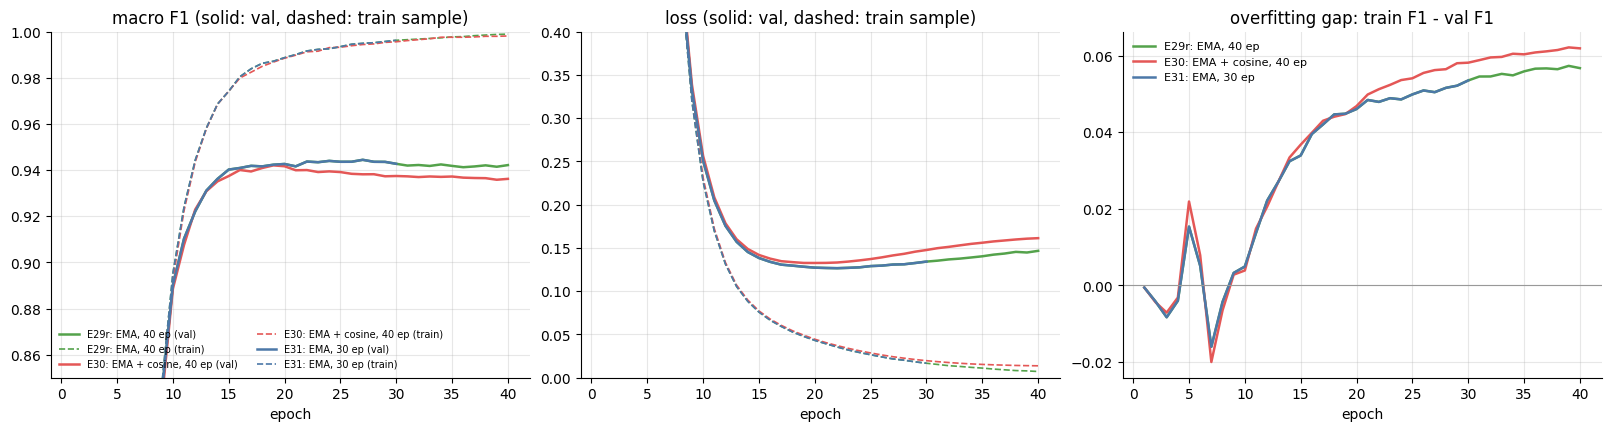

In [16]:
# 셀 8. 그림 (시드 0): 학습·검증 F1, 학습·검증 손실(같은 조건), F1 차이(학습 − 검증)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2), constrained_layout=True)
colors = {"E29r": "#54A24B", "E30": "#E45756", "E31": "#4C78A8"}
names = {"E29r": "E29r: EMA, 40 ep", "E30": "E30: EMA + cosine, 40 ep", "E31": "E31: EMA, 30 ep"}
for r in RUNS:
    if r["시드"] != SEEDS[0]:
        continue
    h = r["hist"]; c = colors[r["번호"]]
    ax[0].plot(h.epoch, h.f1, "-", color=c, lw=1.8, label=names[r["번호"]] + " (val)")
    ax[0].plot(h.epoch, h.train_f1, "--", color=c, lw=1.2, label=names[r["번호"]] + " (train)")
    ax[1].plot(h.epoch, h.val_loss, "-", color=c, lw=1.8)
    ax[1].plot(h.epoch, h.train_loss, "--", color=c, lw=1.2)
    ax[2].plot(h.epoch, h.gap_f1, "-", color=c, lw=1.8, label=names[r["번호"]])
ax[0].set_title("macro F1 (solid: val, dashed: train sample)"); ax[0].set_ylim(0.85, 1.0)
ax[1].set_title("loss (solid: val, dashed: train sample)"); ax[1].set_ylim(0, 0.4)
ax[2].set_title("overfitting gap: train F1 - val F1"); ax[2].axhline(0, color="#999", lw=0.8)
for a in ax:
    a.set_xlabel("epoch"); a.grid(alpha=.3); a.spines[["top", "right"]].set_visible(False)
ax[0].legend(frameon=False, fontsize=7, ncol=2); ax[2].legend(frameon=False, fontsize=8)
os.makedirs("figs", exist_ok=True)
fig.savefig("figs/13_overfitting.png", dpi=150)
plt.show()